# 02 — Feature Engineering and Modeling Preparation

## Purpose

The purpose of this notebook is to prepare the cleaned concrete dataset for
machine-learning model development.

The original dataset contains measurements for concrete ingredients, curing
age, and compressive strength. This notebook will create additional
domain-informed features, define the predictor and target variables, and split
the data into training and test sets.

Because concrete strength depends on the proportions and interactions of its
ingredients, engineered ratio features may provide more useful information
than individual ingredient quantities alone.

## Plan of Attack

1. Load the cleaned dataset produced in Notebook 01.
2. Confirm that the processed data was imported correctly.
3. Create domain-informed features describing concrete composition.
4. Validate the engineered features for missing, infinite, or impossible values.
5. Explore the relationships between engineered features and compressive strength.
6. Separate the predictor variables (`X`) from the target variable (`y`).
7. Divide the data into training and test sets.
8. Preserve the test set for final model evaluation.

## Expected Output

By the end of this notebook, the project will have:

- A modeling-ready dataset
- Reusable feature-engineering code
- Clearly defined predictors and target
- Training and test datasets


In [16]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split


RANDOM_STATE = 42

In [17]:
from pathlib import Path

print(Path.cwd())

c:\Users\kahau\OneDrive\Documents\Techmeup\Week-7\Project\Predicting-Concrete-Compressive-Strength-from-Mix-Composition-and-Curing-Age\Notebooks


In [18]:
df_model = pd.read_csv(
    "../Processed_Data/concrete_cleaned.csv"
)

df_model.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [19]:
print("Dataset shape:", df_model.shape)
print("Missing values:", df_model.isna().sum().sum())
print("Exact duplicates:", df_model.duplicated().sum())

df_model.info()

Dataset shape: (1005, 9)
Missing values: 0
Exact duplicates: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1005 entries, 0 to 1004
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   cement                         1005 non-null   float64
 1   blast_furnace_slag             1005 non-null   float64
 2   fly_ash                        1005 non-null   float64
 3   water                          1005 non-null   float64
 4   superplasticizer               1005 non-null   float64
 5   coarse_aggregate               1005 non-null   float64
 6   fine_aggregate                 1005 non-null   float64
 7   age                            1005 non-null   int64  
 8   concrete_compressive_strength  1005 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 70.8 KB


## Processed Data Validation

The cleaned dataset from Notebook 01 was successfully imported.

Before feature engineering, the dataset was checked to confirm:

- The expected number of rows and columns
- The absence of missing values
- The absence of exact duplicate rows
- The correct numerical data types
- The presence of the target variable, concrete compressive strength

In [20]:
def add_concrete_features(df):
    """
    Add domain-informed features describing concrete mixture composition.

    Parameters
    ----------
    df : pandas.DataFrame
        Cleaned concrete dataset.

    Returns
    -------
    pandas.DataFrame
        Copy of the dataset containing engineered features.
    """
    engineered_df = df.copy()

    engineered_df["binder_total"] = (
        engineered_df["cement"]
        + engineered_df["blast_furnace_slag"]
        + engineered_df["fly_ash"]
    )

    engineered_df["aggregate_total"] = (
        engineered_df["coarse_aggregate"]
        + engineered_df["fine_aggregate"]
    )

    engineered_df["water_binder_ratio"] = (
        engineered_df["water"]
        / engineered_df["binder_total"]
    )

    engineered_df["aggregate_binder_ratio"] = (
        engineered_df["aggregate_total"]
        / engineered_df["binder_total"]
    )

    return engineered_df

In [21]:
df_engineered = add_concrete_features(df_model)

df_engineered.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength,binder_total,aggregate_total,water_binder_ratio,aggregate_binder_ratio
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99,540.0,1716.0,0.30000,3.177778
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89,540.0,1731.0,0.30000,3.205556
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27,475.0,1526.0,0.48000,3.212632
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05,475.0,1526.0,0.48000,3.212632
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30,331.0,1803.9,0.58006,5.449849


In [22]:
engineered_columns = [
    "binder_total",
    "aggregate_total",
    "water_binder_ratio",
    "aggregate_binder_ratio"
]

In [33]:
df_engineered.columns

Index(['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer',
       'coarse_aggregate', 'fine_aggregate', 'age',
       'concrete_compressive_strength', 'binder_total', 'aggregate_total',
       'water_binder_ratio', 'aggregate_binder_ratio'],
      dtype='object')

In [23]:
df_engineered[engineered_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
binder_total,1005.0,406.211144,91.421010,200.000000,336.300000,388.400000,480.000000,640.00
aggregate_total,1005.0,1747.065075,102.232271,1457.000000,1679.000000,1758.300000,1829.000000,1970.00
water_binder_ratio,1005.0,0.473136,0.125497,0.235073,0.389522,0.480000,0.561298,0.90
aggregate_binder_ratio,1005.0,4.564626,1.233545,2.376562,3.476000,4.507895,5.409091,9.85


In [24]:
print(
    "Missing values:",
    df_engineered[engineered_columns].isna().sum().sum()
)

print(
    "Infinite values:",
    np.isinf(
        df_engineered[engineered_columns]
    ).sum().sum()
)

Missing values: 0
Infinite values: 0


In [25]:
zero_binder_count = (
    df_engineered["binder_total"] == 0
).sum()

print("Rows with zero total binder:", zero_binder_count)

Rows with zero total binder: 0


## Engineered Feature Validation

The engineered features were checked for missing, infinite, negative, and
impossible values. No zero binder totals were identified, so the calculated
water-to-binder and aggregate-to-binder ratios are valid for all observations.

The resulting feature ranges were also reviewed before proceeding to model
preparation.

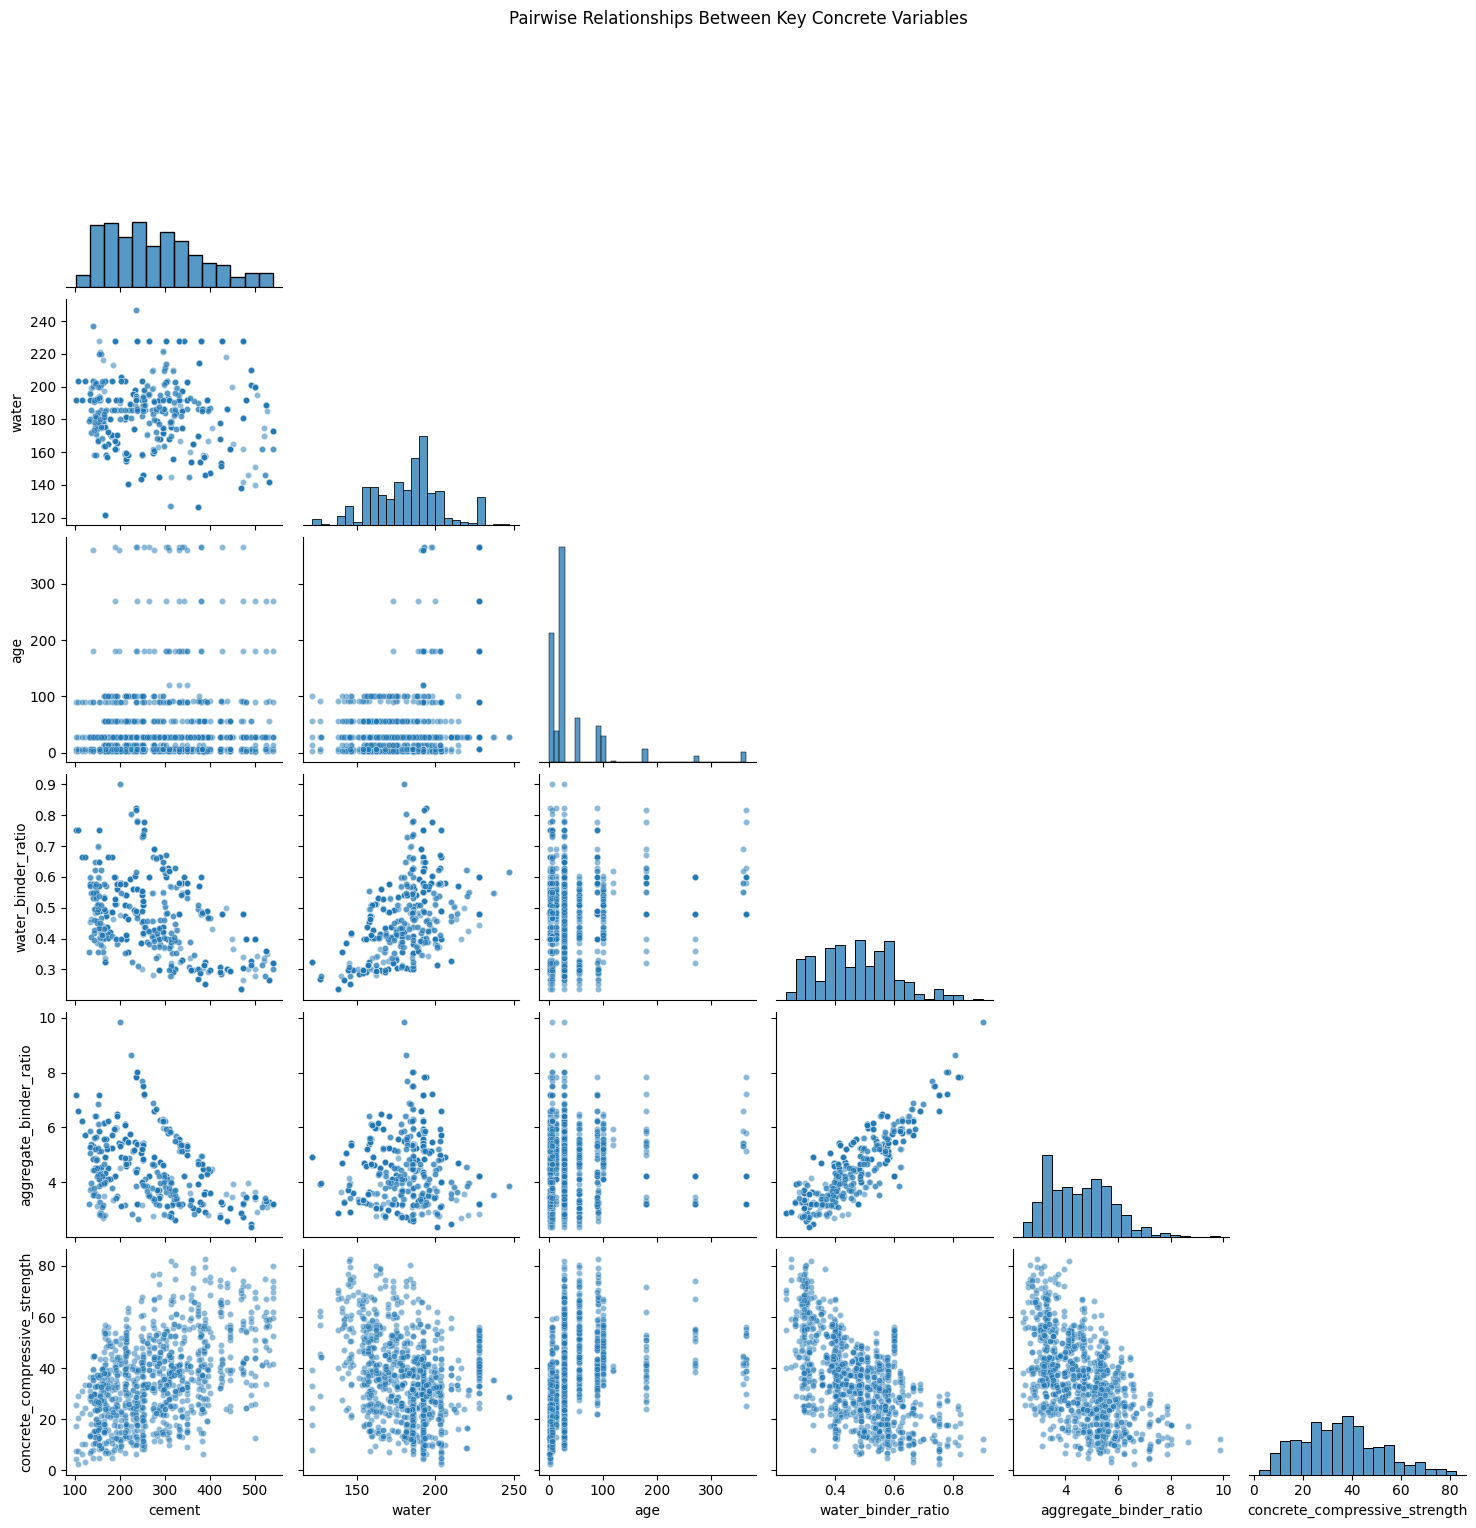

In [26]:
pairplot_columns = [
    "cement",
    "water",
    "age",
    "water_binder_ratio",
    "aggregate_binder_ratio",
    "concrete_compressive_strength"
]

pair_plot = sns.pairplot(
    df_engineered[pairplot_columns],
    corner=True,
    diag_kind="hist",
    plot_kws={
        "alpha": 0.5,
        "s": 20
    }
)

pair_plot.fig.suptitle(
    "Pairwise Relationships Between Key Concrete Variables",
    y=1.02
)

pair_plot.savefig(
    "../Plots/key_concrete_variable_pairplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Pairwise Feature Relationships

The pairplot compares the distributions and relationships of several important
original and engineered variables. Concrete compressive strength generally
increases with cement content and curing age, while higher water-to-binder and
aggregate-to-binder ratios are more often associated with lower strength.

The substantial spread within these relationships indicates that no single
variable fully explains compressive strength. Several relationships also appear
nonlinear, supporting the comparison of linear and tree-based regression models.

In [27]:
engineered_correlations = (
    df_engineered[
        engineered_columns
        + ["concrete_compressive_strength"]
    ]
    .corr()["concrete_compressive_strength"]
    .sort_values(ascending=False)
)

engineered_correlations

concrete_compressive_strength    1.000000
binder_total                     0.598103
aggregate_total                 -0.256342
aggregate_binder_ratio          -0.554550
water_binder_ratio              -0.610843
Name: concrete_compressive_strength, dtype: float64

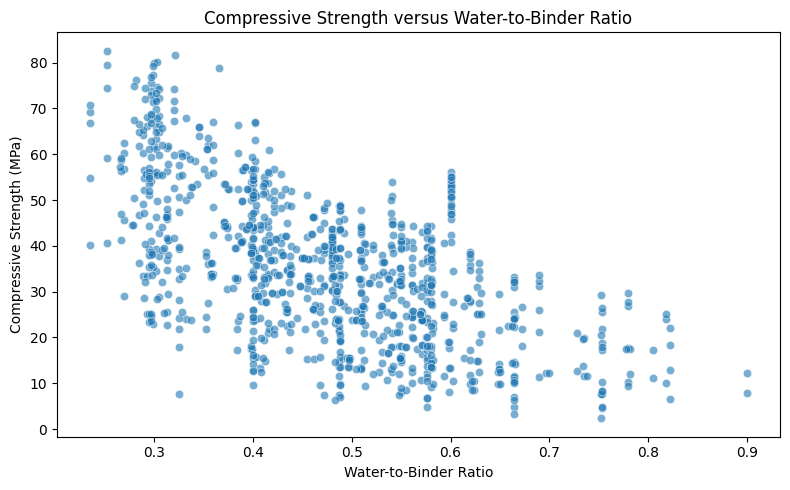

<function matplotlib.pyplot.savefig(*args, **kwargs) -> 'None'>

In [28]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_engineered,
    x="water_binder_ratio",
    y="concrete_compressive_strength",
    alpha=0.6
)

plt.title("Compressive Strength versus Water-to-Binder Ratio")
plt.xlabel("Water-to-Binder Ratio")
plt.ylabel("Compressive Strength (MPa)")

plt.tight_layout()

plt.savefig(
    "../plots/compressive_strength_vs_water_binder_ratio.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.savefig

## Engineered Feature Analysis

The water-to-binder ratio shows how much water is present relative to the
cementitious materials in the concrete mixture.

The plot indicates that mixtures with lower water-to-binder ratios generally
achieve higher compressive strengths, while mixtures with higher ratios tend
to have lower strengths. However, there is still considerable variation,
showing that curing age and the remaining mixture components also influence
strength.

This engineered ratio appears more informative than water content alone and
will therefore be retained as a predictor.

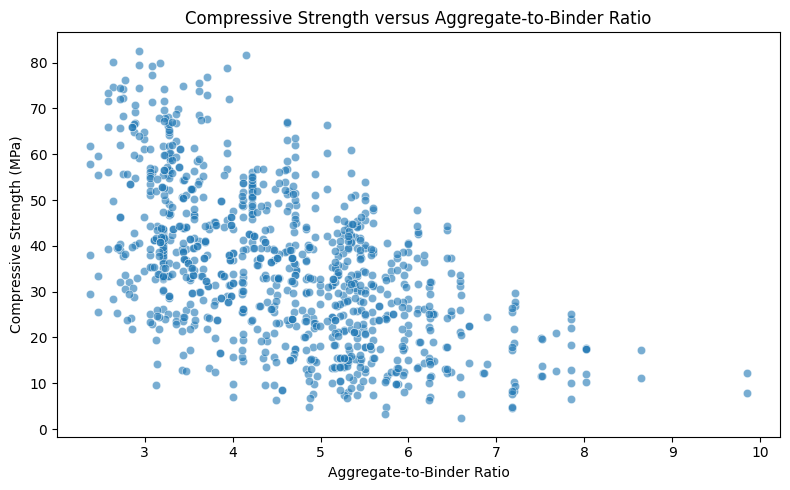

<Figure size 640x480 with 0 Axes>

In [29]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_engineered,
    x="aggregate_binder_ratio",
    y="concrete_compressive_strength",
    alpha=0.6
)

plt.title("Compressive Strength versus Aggregate-to-Binder Ratio")
plt.xlabel("Aggregate-to-Binder Ratio")
plt.ylabel("Compressive Strength (MPa)")

plt.tight_layout()
plt.show()
plt.savefig("../Plots/Compressive Strength versus Aggregate-to-Binder Ratio")

### Aggregate-to-Binder Ratio and Compressive Strength

The plot shows a clear negative relationship between aggregate-to-binder ratio and concrete compressive strength. Mixtures with lower ratios generally achieve higher strength, while higher ratios are mostly associated with lower-strength concrete.

The wide spread of strength values at similar ratios indicates that this feature is important but does not explain strength on its own. Curing age, water content, binder composition, and other mixture characteristics also influence the final result. The relationship also appears somewhat nonlinear, which supports testing tree-based models alongside linear regression.

## Engineered Feature Correlation Heatmap

Notebook 01 examined correlations between the original dataset variables. This
heatmap extends that analysis by including the engineered totals and ratio
features created in this notebook.

Correlation measures the strength of linear relationships between variables.
It helps identify predictors related to compressive strength and highlights
potential overlap between original and engineered features.

### Engineered Feature Correlation Findings

The heatmap identified water-to-binder ratio, total binder content,
aggregate-to-binder ratio, cement content, and curing age as the variables with
the strongest linear relationships with compressive strength.

Several engineered predictors were also strongly correlated with one another.
This is expected because the ratios and totals share several of the same
ingredient measurements.

Although these correlations indicate overlapping information, the iterative
feature-elimination experiment showed that removing predictors did not improve
cross-validation performance. Gradient Boosting was able to use the combined
information effectively, and the complete 12-feature set produced the lowest
prediction error.

The full feature set was therefore retained for the final tuned Gradient
Boosting model.

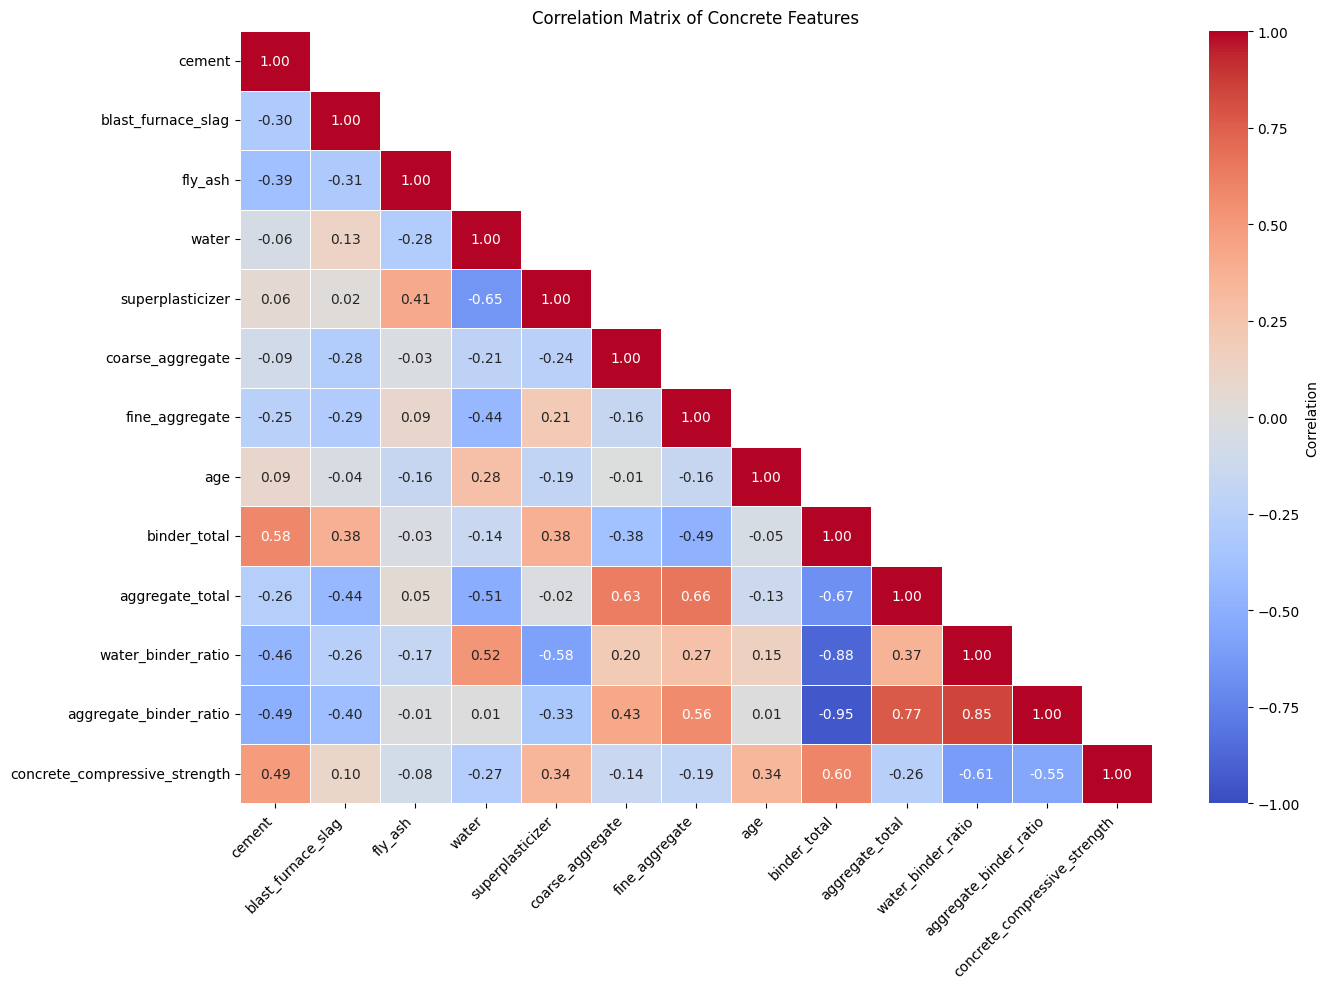

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Put the target last so the heatmap is easier to interpret
ordered_columns = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
    "age",
    "binder_total",
    "aggregate_total",
    "water_binder_ratio",
    "aggregate_binder_ratio",
    "concrete_compressive_strength"
]

# Calculate correlations from the engineered dataframe
correlation_matrix = df_engineered[ordered_columns].corr()

# Hide only the upper triangle while keeping the diagonal
mask = np.triu(
    np.ones_like(correlation_matrix, dtype=bool),
    k=1
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Correlation"}
)

plt.title("Correlation Matrix of Concrete Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../Plots/concrete_feature_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
target_column = "concrete_compressive_strength"

X = df_engineered.drop(columns=target_column)
y = df_engineered[target_column]

In [ ]:
print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Predictor shape: (1005, 12)
Target shape: (1005,)


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,binder_total,aggregate_total,water_binder_ratio,aggregate_binder_ratio
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,540.0,1716.0,0.30000,3.177778
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,540.0,1731.0,0.30000,3.205556
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,475.0,1526.0,0.48000,3.212632
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,475.0,1526.0,0.48000,3.212632
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,331.0,1803.9,0.58006,5.449849


0    79.99
1    61.89
2    40.27
3    41.05
4    44.30
Name: concrete_compressive_strength, dtype: float64

## Predictors and Target

The concrete mixture variables, curing age, and engineered features were
assigned as predictor variables (`X`). Concrete compressive strength was
assigned as the continuous target variable (`y`), confirming that this is a
supervised regression problem.

## Feature-Scaling Decision

The predictor variables have different numerical ranges. For example, concrete
ingredient quantities are measured in kilograms per cubic metre, while the
engineered mixture ratios have much smaller values.

Feature scaling was considered during model preparation. However, the principal
models used in this project—Decision Trees, Random Forest, Bagging, AdaBoost,
and Gradient Boosting—make predictions using threshold-based splits rather than
distance calculations.

These models are largely unaffected by differences in feature scale. The
predictors were therefore retained in their original units, which also makes
the data and model outputs easier to interpret.

Scaling would be required for distance- or gradient-sensitive algorithms such
as K-Nearest Neighbors, Support Vector Machines, PCA, and many neural networks.

In [ ]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (804, 12)
X_test: (201, 12)
y_train: (804,)
y_test: (201,)


## Train-Test Split

The data was divided into an 80% training set and a 20% test set. The training
set will be used for model development, comparison, cross-validation, and
hyperparameter tuning.

The test set will be kept separate until the final model has been selected so
that it can provide an unbiased estimate of performance on unseen data.

In [ ]:
split_comparison = pd.DataFrame({
    "training_set": y_train.describe(),
    "test_set": y_test.describe()
})

split_comparison

,training_set,test_set
count,804.000000,201.00000
mean,35.066978,35.98398
std,16.022924,17.31521
min,3.320000,2.33000
25%,23.222500,23.80000
50%,33.740000,34.57000
75%,44.392500,46.90000
max,79.990000,82.60000


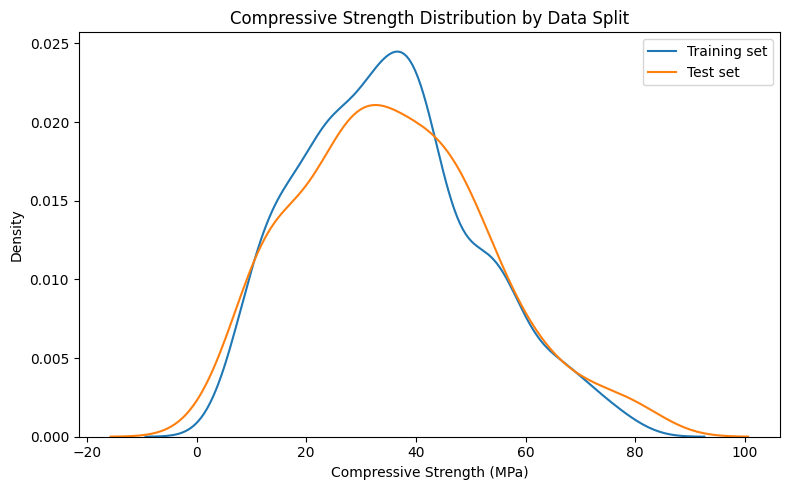

In [ ]:
plt.figure(figsize=(8, 5))

sns.kdeplot(y_train, label="Training set")
sns.kdeplot(y_test, label="Test set")

plt.title("Compressive Strength Distribution by Data Split")
plt.xlabel("Compressive Strength (MPa)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
df_engineered.to_csv(
    "../Processed_Data/concrete_engineered.csv",
    index=False
)

print("Engineered dataset saved.")

Engineered dataset saved.


## Notebook Summary

The cleaned concrete dataset was prepared for machine learning by creating four
domain-informed features:

- Total binder content
- Total aggregate content
- Water-to-binder ratio
- Aggregate-to-binder ratio

The engineered features were validated and showed meaningful relationships with
compressive strength. The predictors and target were then defined, and the data
was divided into training and test sets.

The resulting engineered dataset is now ready for model development. The next
notebook will establish a baseline, compare regression algorithms, and evaluate
model performance using cross-validation.